# Beach safety — EDA before modelling
Two tables: **panel** (beach × month, 80 beaches × 120 months, Sep-2016 → Aug-2026) and **person** (one row per person involved in an incident, joined to that beach-month's covariates).

Goal of the downstream models: frequency (incidents/people per beach-month) × severity (P(severe | person)) → expected severe incidents, to rank where an extra $2M reduces them most.

In [1]:
import pandas as pd, numpy as np, matplotlib.pyplot as plt
import statsmodels.api as sm, statsmodels.formula.api as smf
pd.set_option('display.width', 200); pd.set_option('display.max_columns', 60)
plt.rcParams.update({'figure.dpi': 110, 'axes.spines.top': False, 'axes.spines.right': False,
                     'axes.grid': True, 'grid.alpha': .25, 'font.size': 9})
BLUE, ORANGE, GREY, RED = '#2a6f97', '#e07a2f', '#9aa5b1', '#c0392b'

P = pd.read_csv('/mnt/user-data/uploads/panel.csv')    # adjust paths
Q = pd.read_csv('/mnt/user-data/uploads/person.csv')
for d in (P, Q):
    d['date'] = pd.to_datetime(d['month'], format='%m/%Y')
    d['mo'] = d.date.dt.month
    d['fy'] = d.date.dt.year + (d.mo >= 9)          # season/FY: Sep–Aug, labelled by end year
Q['sev'] = (Q.inc_type == 'Severe').astype(int)
P['sev_any'] = (P.n_severe > 0).astype(int)
print(P.shape, Q.shape, P.date.min().date(), P.date.max().date())

(9600, 38) (33941, 53) 2016-09-01 2026-08-01


## 1. Data integrity — does the join reconcile?

In [2]:
agg = (Q.groupby(['beach_nm','month'])
         .agg(ni=('incident_id','nunique'), npl=('person_no','size'),
              sv=('sev','sum'), cc=('inc_type', lambda s:(s=='CloseCall').sum()),
              md=('inc_type', lambda s:(s=='Mild').sum())).reset_index())
m = P.merge(agg, on=['beach_nm','month'], how='left').fillna(0)
checks = {k: int((m[k]!=m[v]).sum()) for k,v in
          [('n_incidents','ni'),('n_people','npl'),('n_severe','sv'),('n_closecall','cc'),('n_mild','md')]}
checks['dup beach-month keys'] = int(P.duplicated(['beach_nm','month']).sum())
checks['person rows w/o panel match'] = int(len(Q.merge(P[['beach_nm','month']], how='left', indicator=True).query('_merge=="left_only"')))
checks['missing values (panel, person)'] = (int(P.isna().sum().sum()), int(Q.isna().sum().sum()))
checks['incident_size != rows per incident'] = int((Q.groupby('incident_id').size() != Q.groupby('incident_id').incident_size.first()).sum())
checks['incidents with mixed severity across people'] = int((Q.groupby('incident_id').inc_type.nunique()>1).sum())
pd.Series(checks)

n_incidents                                         0
n_people                                            0
n_severe                                            0
n_closecall                                         0
n_mild                                              0
dup beach-month keys                                0
person rows w/o panel match                         0
missing values (panel, person)                 (0, 0)
incident_size != rows per incident                  0
incidents with mixed severity across people       211
dtype: object

Joins are clean: counts reconcile exactly, zeros were filled, covariates match. Note **severity is a person-level attribute** — 211 incidents contain people of different severities, so the severity model should be at person level (with incident as a cluster), not incident level.

Hidden missingness: `surfer` has 1,734 `'unknown'` and `inc_cause` 1,764 `'unknown'` — treat as their own level, not NaN-drop.

## 2. Leakage — `report_lag_days` and `response_min`

In [3]:
print(pd.crosstab(Q.report_lag_days, Q.inc_type))
lagged = Q[Q.report_lag_days>0]
print('\nresponse_min − 1440·lag for lagged rows:')
print((lagged.response_min - 1440*lagged.report_lag_days).describe().round(1))

inc_type         CloseCall   Mild  Severe
report_lag_days                          
0                     3267  30454     168
1                        0      0      18
2                        0      0      15
3                        0      0      13
4                        0      0       6

response_min − 1440·lag for lagged rows:
count    52.0
mean     18.5
std      18.0
min       1.5
25%       4.9
50%      11.1
75%      28.1
max      80.6
dtype: float64


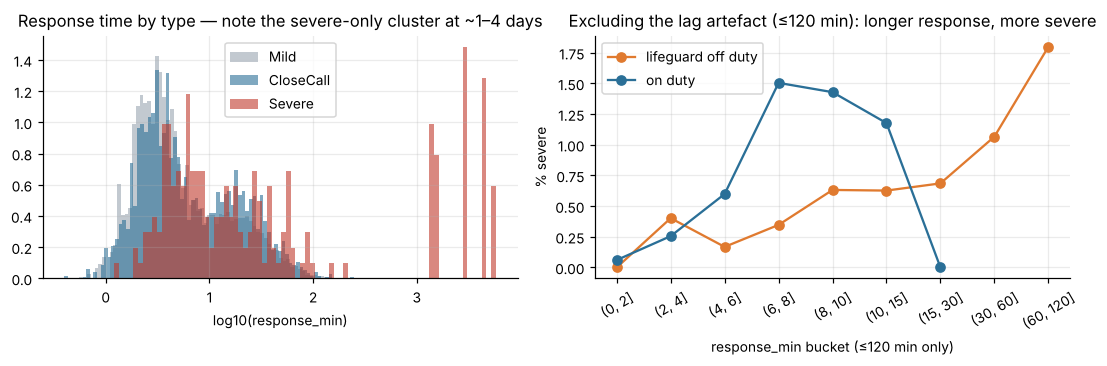

In [4]:
fig, ax = plt.subplots(1, 2, figsize=(10, 3.4))
for t, c in [('Mild', GREY), ('CloseCall', BLUE), ('Severe', RED)]:
    ax[0].hist(np.log10(Q.loc[Q.inc_type==t, 'response_min']), bins=80, alpha=.6, color=c, label=t, density=True)
ax[0].set(xlabel='log10(response_min)', title='Response time by type — note the severe-only cluster at ~1–4 days'); ax[0].legend()
d = Q[Q.response_min<=120].copy(); d['b'] = pd.cut(d.response_min, [0,2,4,6,8,10,15,30,60,120])
r = d.groupby(['on_duty','b'], observed=True).sev.mean().unstack(0)*100
r.plot(ax=ax[1], marker='o', color=[ORANGE, BLUE]); ax[1].set(ylabel='% severe', xlabel='response_min bucket (≤120 min only)',
     title='Excluding the lag artefact (≤120 min): longer response, more severe'); ax[1].legend(['lifeguard off duty','on duty'])
plt.setp(ax[1].get_xticklabels(), rotation=30); plt.tight_layout()

**This is the most important finding for the severity model.**
- `report_lag_days > 0` occurs *only* for severe cases (52 of 220). It's a perfect leak → drop it as a predictor.
- For those rows `response_min` = 1440 × lag + the real response time. Raw `response_min` therefore partly encodes the outcome. Fix: `response_clean = response_min − 1440·report_lag_days` (but that still uses the lag, which you only know *because* it's severe — so even the cleaned value is conditionally suspect).
- More fundamentally, response time is **post-incident and a mediator** of the levers you're allocating money to (lifeguards/drones → faster response → lower severity). If you include it alongside `lg_hrs`/`drone_hrs`, the model will attribute their effect to response time and under-credit the funded levers. Decide what question each model answers:
  - *Mechanism model* (does faster response reduce severity?) → include cleaned response time.
  - *Policy model* (what does $X of lifeguard/drone buy?) → exclude it; use pre-incident levers only.
- Also an actuarial footnote: because severe cases have up to 4-day reporting lag and reports end 31-Aug-2026, a handful of late-August 2026 severe incidents may be IBNR (not yet reported). Small, but worth one sentence in a Taylor Fry deck.

## 3. The target is rare

In [5]:
s = pd.Series({'people': len(Q), 'severe people': int(Q.sev.sum()), 'severe share %': round(Q.sev.mean()*100,2),
               'beach-months with ≥1 severe': int(P.sev_any.sum()), 'beach-months': len(P),
               'beaches with 0 severe in 10 yrs': int((P.groupby('beach_nm').n_severe.sum()==0).sum())})
print(s.to_string()); print('\nn_severe per beach-month:', P.n_severe.value_counts().sort_index().to_dict())
for c in ['n_incidents','n_people','n_severe']:
    print(f'{c:12s} mean={P[c].mean():.3f} var={P[c].var():.2f} zeros={np.mean(P[c]==0):.1%}')

people                             33941.00
severe people                        220.00
severe share %                         0.65
beach-months with ≥1 severe          204.00
beach-months                        9600.00
beaches with 0 severe in 10 yrs       30.00

n_severe per beach-month: {0: 9396, 1: 192, 2: 10, 3: 1, 5: 1}
n_incidents  mean=3.381 var=45.88 zeros=38.5%
n_people     mean=3.536 var=50.56 zeros=38.5%
n_severe     mean=0.023 var=0.03 zeros=97.9%


220 severe events total, ~22/year. Consequences:
- A direct severe-count model has ~200 non-zero cells: it can support **few** predictors. Frequency × severity decomposition borrows strength from the 33.9k mild/close-call records, which is why your two-table setup is the right call.
- `n_people` is heavily overdispersed (var/mean ≈ 14) with 38.5% zeros → negative binomial with `log(visitors)` offset, not Poisson. Check whether the zeros are explained by low visitors before reaching for zero-inflation.
- With so few events, any beach-level severity effect needs shrinkage (random effect / partial pooling). 30 beaches have zero severe events in 10 years — raw rates will be 0 for them, which is not credible.

## 4. Time: trend and seasonality

,visitors,people,severe,lg_hrs,drone_hrs,campaign,people_per_100k_vis,severe_per_1k_people
fy,,,,,,,,
2017,24515073,3511,30,519765.3,0.0,0.09,14.32,8.54
2018,24883355,3603,36,516990.4,5325.5,0.12,14.48,9.99
2019,25569807,3662,27,531155.4,4973.3,0.13,14.32,7.37
2020,23162283,2623,13,518807.3,12777.7,0.17,11.32,4.96
2021,23100162,2549,13,512334.4,13195.8,0.15,11.03,5.10
2022,23472232,2938,19,501147.9,12991.5,0.14,12.52,6.47
2023,27284788,3546,17,519830.5,24271.8,0.14,13.00,4.79
2024,28388859,3707,21,558790.8,24362.7,0.16,13.06,5.66
2025,28640796,3947,18,620098.4,29551.7,0.15,13.78,4.56


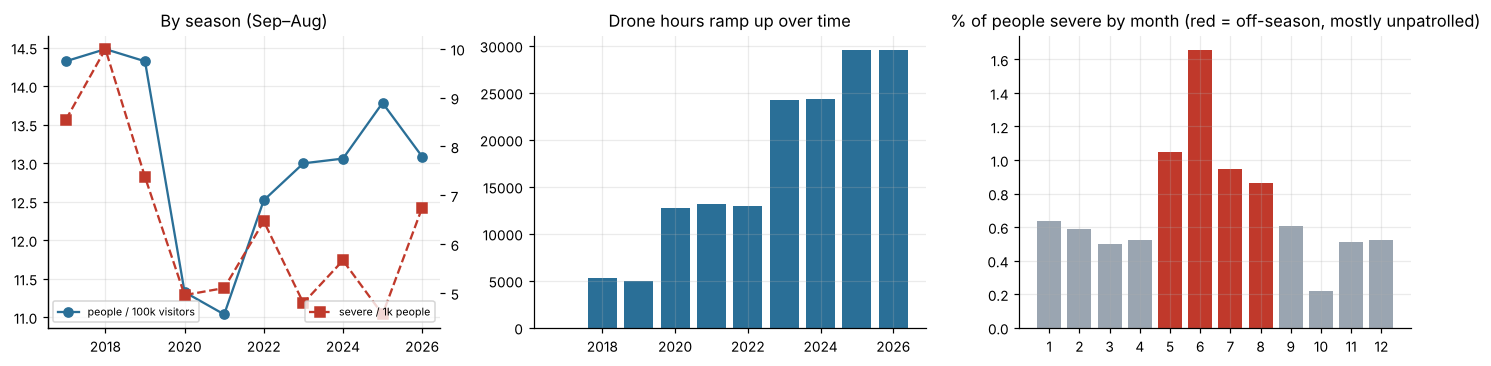

In [6]:
fy = P.groupby('fy').agg(visitors=('visitors','sum'), people=('n_people','sum'), severe=('n_severe','sum'),
                       lg_hrs=('lg_hrs','sum'), drone_hrs=('drone_hrs','sum'), campaign=('campaign_idx','mean'))
fy['people_per_100k_vis'] = fy.people/fy.visitors*1e5; fy['severe_per_1k_people'] = fy.severe/fy.people*1e3
mo = Q.groupby('mo').agg(people=('sev','size'), sev_share=('sev','mean'))
mo = mo.join(P.groupby('mo').agg(visitors=('visitors','mean'), patrolled=('patrolled','mean')))
fig, ax = plt.subplots(1, 3, figsize=(13, 3.4))
ax[0].plot(fy.index, fy.people_per_100k_vis, 'o-', color=BLUE, label='people / 100k visitors')
a2 = ax[0].twinx(); a2.plot(fy.index, fy.severe_per_1k_people, 's--', color=RED, label='severe / 1k people'); a2.grid(False)
ax[0].set_title('By season (Sep–Aug)'); ax[0].legend(loc='lower left', fontsize=7); a2.legend(loc='lower right', fontsize=7)
ax[1].bar(fy.index, fy.drone_hrs, color=BLUE); ax[1].set_title('Drone hours ramp up over time')
ax[2].bar(mo.index, mo.sev_share*100, color=[RED if p<.5 else GREY for p in mo.patrolled])
ax[2].set(title='% of people severe by month (red = off-season, mostly unpatrolled)', xticks=range(1,13))
plt.tight_layout(); fy.round(2)

- Frequency per visitor is fairly stable; the severe share fell after 2019 (≈ drone rollout and the FY2020–21 visitor dip — confounded with time, so don't read it causally without a time control).
- **Seasonality is strong and goes the opposite way for frequency vs severity.** Summer has the most incidents; winter (May–Aug) has the highest *severe share* (≈1–1.7% vs ≈0.5%). In winter only 12% of beach-months are patrolled.
- `patrolled` is almost entirely a calendar variable: 54 beaches are patrolled Sep–Apr only, 10 all year, 16 never. Within a beach, patrolled ⇔ season, so its "effect" is not separately identified from season except via the 26 always/never beaches. Include month (or season) fixed effects, or the patrol coefficient will soak up winter conditions (cold water, fewer bystanders, swell).

## 5. Beaches: where are the severe incidents?

              beaches  severe  visitors_m  people  sev_per_m_vis  sev_per_1k_people
patrol_group                                                                       
Sep–Apr            54     115      105.94   15342           1.09               7.50
all year           10      98      148.66   17971           0.66               5.45
never              16       7        3.88     628           1.80              11.15


,severe,people,visitors,patrolled,lg_hrs,drone,rocky,n_rips,sev_per_m_vis,patrol_group
beach_nm,,,,,,,,,,
Seven Mile Beach (Lennox Head),22,1442,4228693,0.67,272.55,53.92,1,3.0,5.20,Sep–Apr
North Wollongong Beach,14,1779,14368577,1.00,1635.76,0.00,0,1.6,0.97,all year
Terrigal Beach,13,1397,19338008,1.00,1703.66,11.86,0,1.5,0.67,all year
Bondi Beach,12,3852,17830164,1.00,1826.45,49.31,0,3.1,0.67,all year
Dee Why Beach,12,2265,12644965,1.00,1602.60,61.18,0,1.8,0.95,all year
Byron Bay (Main Beach),11,1703,10966517,1.00,1784.94,22.80,1,2.7,1.00,all year
Palm Beach,11,1658,13214544,1.00,1636.19,28.56,0,1.6,0.83,all year
Maroubra Beach,9,1276,16972837,1.00,1616.39,11.34,1,0.1,0.53,all year
Copacabana Beach,8,777,4523526,0.67,267.99,0.00,0,2.5,1.77,Sep–Apr


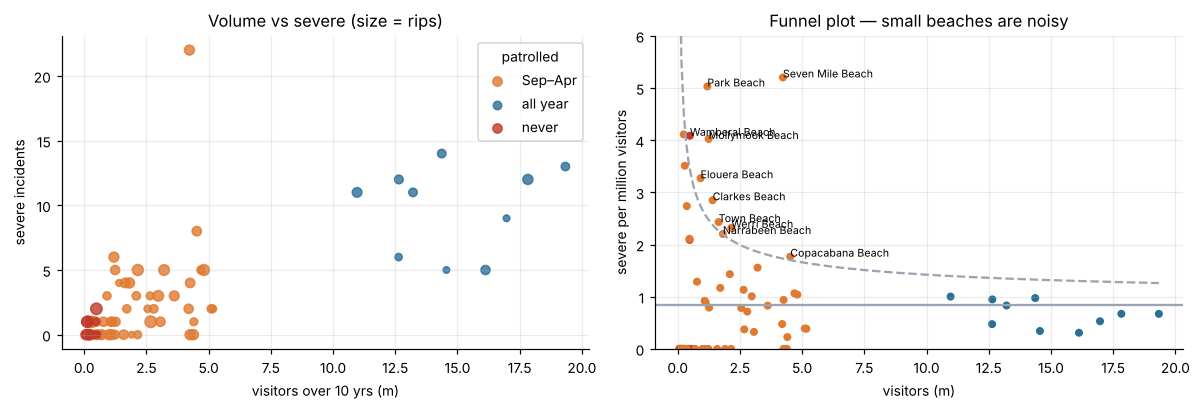

In [7]:
b = P.groupby('beach_nm').agg(severe=('n_severe','sum'), people=('n_people','sum'), visitors=('visitors','sum'),
                             patrolled=('patrolled','mean'), lg_hrs=('lg_hrs','mean'), drone=('drone_hrs','mean'),
                             rocky=('rocky','first'), n_rips=('n_rips','first'))
b['sev_per_m_vis'] = b.severe/b.visitors*1e6
b['patrol_group'] = b.patrolled.map(lambda x: 'never' if x==0 else 'all year' if x==1 else 'Sep–Apr')
fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
col = {'never': RED, 'Sep–Apr': ORANGE, 'all year': BLUE}
for g, d in b.groupby('patrol_group'):
    ax[0].scatter(d.visitors/1e6, d.severe, s=18+d.n_rips*8, color=col[g], label=g, alpha=.8)
ax[0].set(xlabel='visitors over 10 yrs (m)', ylabel='severe incidents', title='Volume vs severe (size = rips)'); ax[0].legend(title='patrolled')
# funnel plot: severe per visitor vs exposure, with Poisson 95% band around the pooled rate
rate = b.severe.sum()/b.visitors.sum(); x = np.linspace(b.visitors.min(), b.visitors.max(), 200)
ax[1].scatter(b.visitors/1e6, b.sev_per_m_vis, color=[col[g] for g in b.patrol_group], s=18)
ax[1].plot(x/1e6, (rate + 1.96*np.sqrt(rate/x))*1e6, '--', color=GREY); ax[1].axhline(rate*1e6, color=GREY)
ax[1].set(xlabel='visitors (m)', ylabel='severe per million visitors', title='Funnel plot — small beaches are noisy', ylim=(0, 6))
for n, r in b[b.sev_per_m_vis > (rate+1.96*np.sqrt(rate/b.visitors))*1e6].iterrows():
    ax[1].annotate(n.split(' (')[0], (r.visitors/1e6, r.sev_per_m_vis), fontsize=7)
plt.tight_layout()
print(b.groupby('patrol_group').agg(beaches=('severe','size'), severe=('severe','sum'), visitors_m=('visitors', lambda v: v.sum()/1e6),
      people=('people','sum')).assign(sev_per_m_vis=lambda d: d.severe/d.visitors_m, sev_per_1k_people=lambda d: d.severe/d.people*1e3).round(2))
b.sort_values('severe', ascending=False).head(12).round(2)

- Severe incidents are concentrated: the top 10 beaches hold ~54%. **Seven Mile Beach (Lennox Head)** stands out — 22 severe, 5 per million visitors (≈ 6× the pooled rate), seasonal patrol, rocky, 3 rips. Park Beach (Coffs) and Mollymook are similar small-but-risky outliers. These are the obvious first candidates for marginal funding, *if* the model confirms it after shrinkage.
- Big urban beaches (Bondi, Manly) have lots of incidents but low severe share — high exposure, well covered. Ranking by raw counts and by rate give different answers; your allocation objective (minimise total severe) means you want **expected severe averted per dollar**, which depends on both exposure and the marginal effect of the lever there.

## 6. The levers: is there enough variation to estimate their effects?

              share of beach-months > 0  beaches ever > 0  within-beach share of variance
lg_hrs                             0.57                64                            0.49
drone_hrs                          0.23                35                            0.64
campaign_idx                       0.24                80                            0.98

lg_hrs when patrolled==0: 0.0 | corr(lg_hrs, patrolled) = 0.6


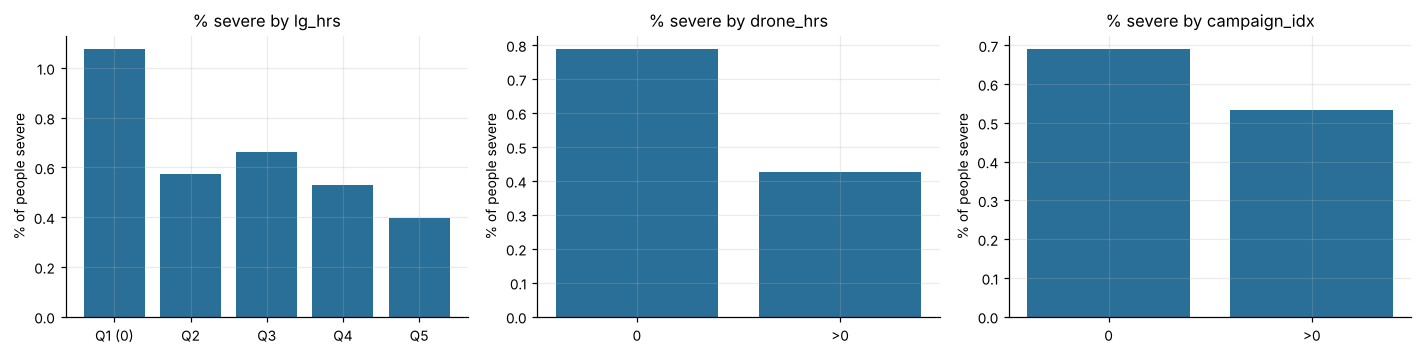

In [8]:
lev = pd.DataFrame({
  'share of beach-months > 0': [(P.lg_hrs>0).mean(), (P.drone_hrs>0).mean(), (P.campaign_idx>0).mean()],
  'beaches ever > 0': [(P.groupby('beach_nm')[c].max()>0).sum() for c in ['lg_hrs','drone_hrs','campaign_idx']],
  'within-beach share of variance': [P.groupby('beach_nm')[c].transform(lambda s: s-s.mean()).var()/P[c].var()
                                       for c in ['lg_hrs','drone_hrs','campaign_idx']]},
  index=['lg_hrs','drone_hrs','campaign_idx']).round(2)
print(lev)
print('\nlg_hrs when patrolled==0:', P.loc[P.patrolled==0,'lg_hrs'].max(), '| corr(lg_hrs, patrolled) =', round(P.lg_hrs.corr(P.patrolled),2))
fig, ax = plt.subplots(1, 3, figsize=(13, 3.3))
for a, c in zip(ax, ['lg_hrs','drone_hrs','campaign_idx']):
    x = pd.qcut(Q[c].rank(method='first'), 5, labels=['Q1 (0)','Q2','Q3','Q4','Q5']) if c=='lg_hrs' else (Q[c]>0).map({False:'0', True:'>0'})
    t = Q.groupby(x).sev.mean()*100
    a.bar(t.index.astype(str), t.values, color=BLUE); a.set(title=f'% severe by {c}', ylabel='% of people severe')
plt.tight_layout()

- **Lifeguard hours** vary a lot, but mostly *between beaches and seasons*; lg_hrs is exactly 0 whenever unpatrolled (corr with `patrolled` ≈ 0.9). Raw association with severe share is strongly negative, but it's confounded: lifeguards are deployed where/when it's busy and safer (summer, calm metropolitan beaches). Any credible effect must condition on season, visitors, swell/rips and beach.
- **Drones** were rolled out in a staggered way to 35 beaches from 2017 onward. That's your best natural experiment: a within-beach before/after comparison (beach + time fixed effects, difference-in-differences style). Raw: severe share ≈ 0.2% with drones vs 0.8% without. At person level `drone_present='Y'` also cuts median response time when lifeguards are off duty (≈7 vs 17 min).
- **Campaigns** are active in 23.5% of beach-months; raw association also negative. Check whether campaigns targeted high-risk beaches (selection) before believing the sign/size.
- The model will only tell you something useful for allocation if you can price these: you'll need cost per lifeguard hour / drone hour / campaign unit from the brief, otherwise you can rank but not optimise the $2M.

## 7. Person-level severity drivers

           mean  sum  size
age_b                     
(0, 12]    0.80   32  4016
(12, 17]   0.82   23  2788
(17, 25]   0.46   34  7404
(25, 40]   0.49   39  7932
(40, 55]   0.47   27  5723
(55, 65]   1.05   42  4007
(65, 110]  1.11   23  2071
            mean  sum   size
inc_hour                    
7–19h     0.0062  197  31795
night     0.0107   23   2146


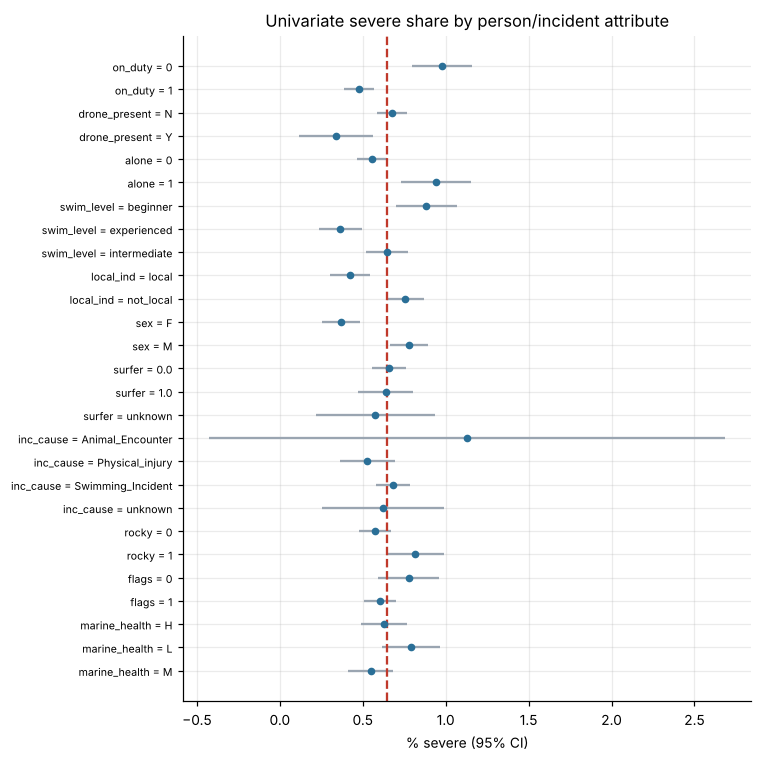

In [9]:
cats = ['on_duty','drone_present','alone','swim_level','local_ind','sex','surfer','inc_cause','rocky','flags','marine_health']
rows = []
for c in cats:
    g = Q.groupby(c).sev.agg(['mean','sum','size'])
    for k, r in g.iterrows(): rows.append((c, str(k), r['mean']*100, int(r['sum']), int(r['size'])))
T = pd.DataFrame(rows, columns=['feature','level','% severe','severe','n'])
fig, ax = plt.subplots(figsize=(7, 7))
lab = T.feature + ' = ' + T.level
se = np.sqrt(T['% severe']/100*(1-T['% severe']/100)/T.n)*100
ax.errorbar(T['% severe'], range(len(T)), xerr=1.96*se, fmt='o', color=BLUE, ecolor=GREY, ms=4)
ax.axvline(Q.sev.mean()*100, color=RED, ls='--'); ax.set_yticks(range(len(T))); ax.set_yticklabels(lab, fontsize=7)
ax.invert_yaxis(); ax.set(xlabel='% severe (95% CI)', title='Univariate severe share by person/incident attribute')
plt.tight_layout()
Q['age_b'] = pd.cut(Q.age, [0,12,17,25,40,55,65,110])
print((Q.groupby('age_b', observed=True).sev.agg(['mean','sum','size']).assign(mean=lambda d: d['mean']*100)).round(2))
print((Q.groupby(Q.inc_hour.between(7,19).map({True:'7–19h', False:'night'})).sev.agg(['mean','sum','size'])).round(4))

Univariate (not causal) signals, roughly in order of size: lifeguard **off duty** (≈1.0% vs 0.5%), **alone** (0.94% vs 0.56%), **beginner** swimmer (0.88% vs experienced 0.37%), **non-local** (0.76% vs 0.42%), **male** (0.78% vs 0.37%), **age U-shape** (children and 55+ highest), rocky beach, no flags, low marine health, swell max > 2.1 m, night hours.

Most person-level attributes (age, sex, local, swim level) are **not fundable levers** — they matter for adjustment and for targeting education campaigns (e.g. non-locals, older swimmers), not as policy variables. `on_duty` is the person-level face of lifeguard coverage and is directly linked to funding.

## 8. Collinearity among covariates

swell_avg_m      swell_max_m        0.97
visitors         n_bins             0.92
lg_hrs           patrolled          0.89
air_temp_hi      water_temp         0.79
visitors         icecream_visits    0.74
icecream_visits  air_temp_hi        0.73
visitors         lg_hrs             0.69
icecream_visits  lg_hrs             0.68
rain_mm          turbidity          0.66
tourist_ratio    first_aid_cap     -0.64
icecream_visits  patrolled          0.61
dtype: float64

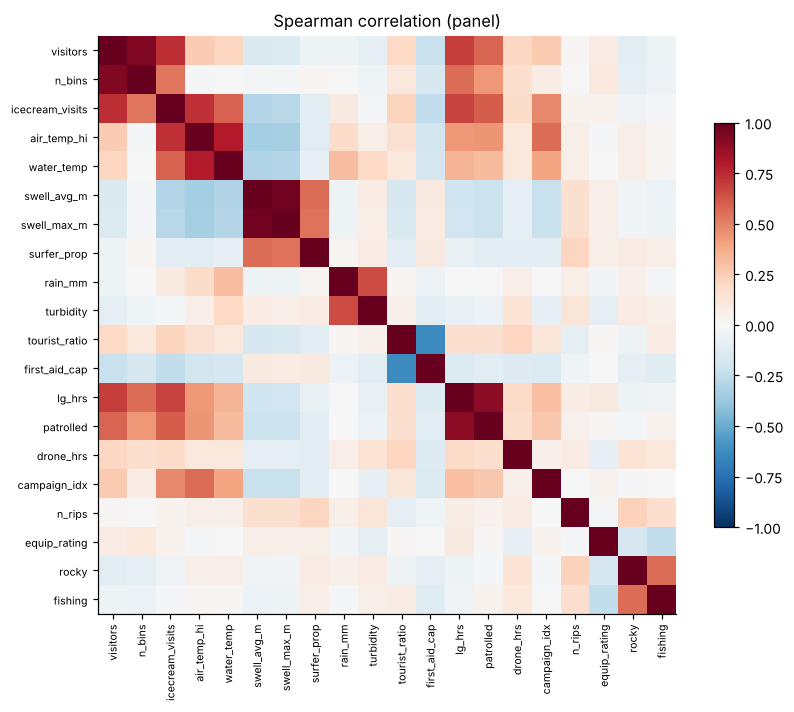

In [10]:
num = P[['visitors','n_bins','icecream_visits','air_temp_hi','water_temp','swell_avg_m','swell_max_m','surfer_prop','rain_mm','turbidity',
         'tourist_ratio','first_aid_cap','lg_hrs','patrolled','drone_hrs','campaign_idx','n_rips','equip_rating','rocky','fishing']]
c = num.corr(method='spearman')
fig, ax = plt.subplots(figsize=(8, 6.5)); im = ax.imshow(c, cmap='RdBu_r', vmin=-1, vmax=1)
ax.set_xticks(range(len(c))); ax.set_xticklabels(c.columns, rotation=90, fontsize=7); ax.set_yticks(range(len(c))); ax.set_yticklabels(c.columns, fontsize=7)
plt.colorbar(im, shrink=.7); ax.set_title('Spearman correlation (panel)'); ax.grid(False); plt.tight_layout()
pairs = c.where(np.triu(np.ones(c.shape), 1).astype(bool)).stack()
pairs[pairs.abs() > .6].sort_values(key=abs, ascending=False).round(2)

Redundant groups — keep one from each:
- `swell_avg_m` ~ `swell_max_m` (0.97) → keep `swell_max_m` (it's the one with the severe signal).
- `visitors` ~ `n_bins` (0.92) ~ `icecream_visits` (0.74) → `n_bins` and `icecream_visits` are proxies for crowding; drop them, use `log(visitors)` as offset. (Ice-cream visits "protecting" against severity is a crowd/summer proxy — a nice slide-friendly example of confounding, but don't put it in the model.)
- `lg_hrs` ~ `patrolled` (0.89) → use `lg_hrs` (continuous, fundable), or `patrolled` + `lg_hrs` given patrolled.
- `air_temp_hi` ~ `water_temp` (0.79) and both with season → pick one plus month effects.
- `rain_mm` ~ `turbidity` (0.66).
- Static beach attributes (`n_rips`, `rocky`, `fishing`, `rockpool`, `shore_len_m`) are perfectly collinear with a beach fixed effect — use a beach random effect if you want both.

## 9. What this means for the models

**Frequency model (panel):** NB GLM / GLMM on `n_people` (or `n_incidents`) with `offset(log(visitors))`, month/season effects, swell, rips, rocky, levers (`lg_hrs`, `drone_hrs`, `campaign_idx`), beach random intercept. Check whether the 38.5% zeros are explained by low winter visitors before adding zero-inflation.

**Severity model (person):** logistic GLMM on `sev` with pre-incident covariates, beach random effect (shrinks the 30 zero-severe beaches sensibly), month/season. Exclude `report_lag_days`; exclude or clean `response_min` depending on whether you want the policy or mechanism view. ~220 events → keep it to roughly 10–20 parameters, or use penalisation / weakly informative priors. Validate with time-based holdout (e.g. train to FY2024, test FY2025–26), not random split, and use calibration + log-loss rather than accuracy (a model predicting 'never severe' is 99.35% accurate).

**Allocation:** expected severe = E[people] × P(severe). The $2M decision needs the *marginal* effect of each lever at each beach and the unit costs. The levers' raw associations are heavily confounded with season and beach, so the drone staggered rollout (within-beach before/after) is your most defensible source of a causal estimate; present lifeguard and campaign effects with that caveat.